# Семёнов А.В. МПИ25-1-1 КР

Задание 46. Обучить любую модель машинного обучения на датасете Kaggle.

Цель: классификация вида ириса по четырём измерениям цветка. Используется логистическая регрессия.

Источник: [Датасет видов Ириса](https://www.kaggle.com/datasets/uciml/iris). Набор содержит 150 объектов и три класса.

## 1. Импорт библиотек

In [13]:
import io
import hashlib
import platform
from importlib.metadata import version
import pandas as pd
import sklearn
from pathlib import Path
import matplotlib.pyplot as plt
import joblib
%pip install kagglehub
import kagglehub
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, ConfusionMatrixDisplay

RANDOM_STATE = 42

for package in ["numpy", "pandas", "scipy", "scikit-learn", "joblib"]:
    print(package + "==" + version(package))

numpy==2.4.6
pandas==3.0.2
scipy==1.18.0
scikit-learn==1.8.0
joblib==1.5.3


## 2. Загрузка и проверка данных

In [2]:
path = kagglehub.dataset_download("uciml/iris")
csv_path = Path(path) / "Iris.csv"

df = pd.read_csv(csv_path)

print("Файл:", csv_path)
print("Размер:", df.shape)
display(df.head())
print("Пропуски:", df.isna().sum().sum())
print(df["Species"].value_counts())

/lib/python3.14/site-packages/kagglehub/clients.py:268: TqdmMonitorWarning: tqdm:disabling monitor support (monitor_interval = 0) due to:
can't start new thread
  with tqdm(total=total_size, initial=size_read, unit="B", unit_scale=True, unit_divisor=1024) as progress_bar:
100%|██████████| 3.60k/3.60k [00:00<00:00, 3.69MB/s]


Extracting files...
Файл: /home/pyodide/.cache/kagglehub/datasets/uciml/iris/versions/2/Iris.csv
Размер: (150, 6)


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


Пропуски: 0
Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64


## 3. Разделение выборки

In [4]:
features = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]
X = df[features]
y = df["Species"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)
print("Обучение:", len(X_train), "Тест:", len(X_test))

Обучение: 120 Тест: 30


## 4. Обучение модели (логистическая регрессия)

In [5]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
])
model.fit(X_train, y_train)
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
print("Модели обучены.")

Модели обучены.


## 5. Оценка качества

,Модель,Accuracy,Macro-F1
0,DummyClassifier,0.3333,0.1667
1,LogisticRegression,0.9333,0.9333


                 precision    recall  f1-score   support

    Iris-setosa      1.000     1.000     1.000        10
Iris-versicolor      0.900     0.900     0.900        10
 Iris-virginica      0.900     0.900     0.900        10

       accuracy                          0.933        30
      macro avg      0.933     0.933     0.933        30
   weighted avg      0.933     0.933     0.933        30



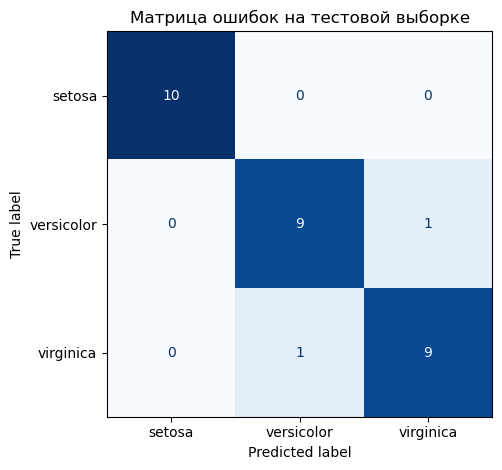

In [6]:
pred = model.predict(X_test)
base_pred = baseline.predict(X_test)
results = pd.DataFrame([
    {"Модель": "DummyClassifier", "Accuracy": accuracy_score(y_test, base_pred),
     "Macro-F1": f1_score(y_test, base_pred, average="macro")},
    {"Модель": "LogisticRegression", "Accuracy": accuracy_score(y_test, pred),
     "Macro-F1": f1_score(y_test, pred, average="macro")}
])
display(results.round(4))
print(classification_report(y_test, pred, digits=3, zero_division=0))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred, cmap="Blues", colorbar=False,
    display_labels=["setosa", "versicolor", "virginica"]
)
plt.title("Матрица ошибок на тестовой выборке")
plt.tight_layout()
plt.show()

## 6. Пример предсказания и сохранение модели

In [7]:
example = X_test.iloc[[0]]
display(example)
print("Предсказанный класс:", model.predict(example)[0])
print("Фактический класс:", y_test.iloc[0])
joblib.dump(model, "iris_model.joblib")

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm
38,4.4,3.0,1.3,0.2


Предсказанный класс: Iris-setosa
Фактический класс: Iris-setosa


['iris_model.joblib']